# Probing Cycle

Demonstrating and quantifying the variation in optimal treatment strategy between patients.

Show both different treatment curves, and also different dependence on tau.

In [1]:
import os
import re
import sys
import pickle
import numpy as np
import pandas as pd
import scipy as sc
import matplotlib.pyplot as plt
from matplotlib.ticker import Locator, MaxNLocator
from matplotlib.colors import LogNorm, to_rgb
from matplotlib import colormaps
from lmfit import minimize, Parameters
from tqdm import tqdm

sys.path.append("../utils")
from myUtils import test_progression, TruncateDataframe, ExtractTreatmentFromDf, LoadPatientData, calc_critical_treatment_threshold, GetPatientIDs
from fittingUtils import residual, compute_r_sq, load_fit, generate_fitSummaryDf
from plotUtils import PlotDrug, PlotData, convert_to_rgb_grayscale, redistribute_rgb
from odeModels import LotkaVolterraModel

In [2]:
# Defaults for plotting
plt.style.use(["classic", "../paper_figures/paper.mplstyle"])
plt.rcParams['font.size'] = '18'

colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_82368/884701199.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_xticklabels([''] + list(colors.keys()));


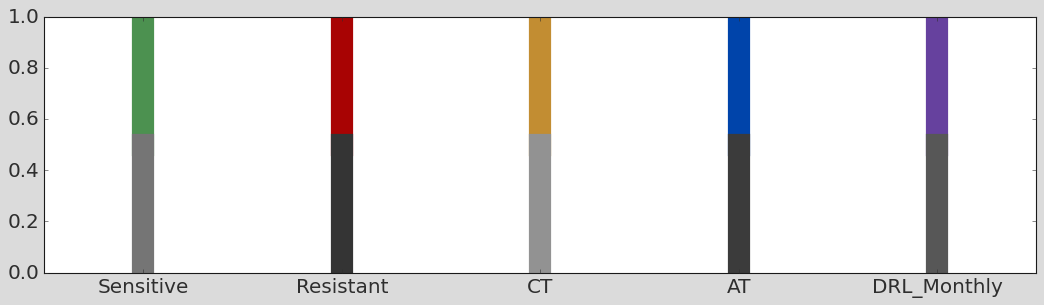

In [3]:
# Defaults for plotting
colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

fig, ax = plt.subplots(1, 1, figsize=(16, 4))
for i, col in enumerate(colors.values()):
    plt.axvline(i+1, 0.5, 1, color = col, linewidth=20)
    plt.axvline(i+1, 0, 0.5, color = convert_to_rgb_grayscale(col), linewidth=20)
plt.xlim(0.5, len(colors.values()) + 0.5)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.gca().set_xticklabels([''] + list(colors.keys()));

In [4]:
file_path = os.path.dirname(os.path.abspath("__file__"))
out_dir = os.path.join(os.pardir, "patients", "Bruchovsky_et_al", "Prog_fits")

RERUN_FITTING = True

In [5]:
def SimulateFit(fit_params, dataDf, dt=1, solver_kws={}):
    myModel = LotkaVolterraModel()
    myModel.SetParams(**fit_params)
    myModel.Simulate(treatmentScheduleList=ExtractTreatmentFromDf(dataDf),**solver_kws)
    # Interpolate to the desired time grid
    t_eval = np.arange(0, myModel.resultsDf.Time.max(), dt)
    trimmedResultsDic = {'Time': t_eval}
    for variable in ['S', 'R', 'TumourSize', 'DrugConcentration']:
        f = sc.interpolate.interp1d(myModel.resultsDf.Time, myModel.resultsDf[variable])
        trimmedResultsDic = {**trimmedResultsDic, variable: f(t_eval)}
    myModel.resultsDf = pd.DataFrame(trimmedResultsDic)
    return myModel

In [6]:
def Plot_method(df, legend=False, drug_label="Drug Concentration",
         ax=None, linewidth=5, drug_color = 'k', colors = None, **kwargs):
    if ax is None: fig, ax = plt.subplots(1, 1)
    linestyles = ['-', (0, (10,10)), (0, (5,5))]
    for i, var in enumerate(["TumourSize", 'S', 'R']):
        ax.plot(df['Time'], df[var], linewidth=linewidth, linestyle=linestyles[i], color=colors[var], **kwargs)

    PlotDrug(df, ax, drug_color, plotDrugAsBar = True, currDrugBarPosition = 1.25)

    # Format the plot
    ax.set_title(kwargs.get('title', ''))
    ax.yaxis.get_major_ticks()[-1].set_visible(False); ax.tick_params(right = False, top = False)

## Patient Datasets

Loaded Patient IDs: [12, 20, 25, 78, 85, 99, 101]


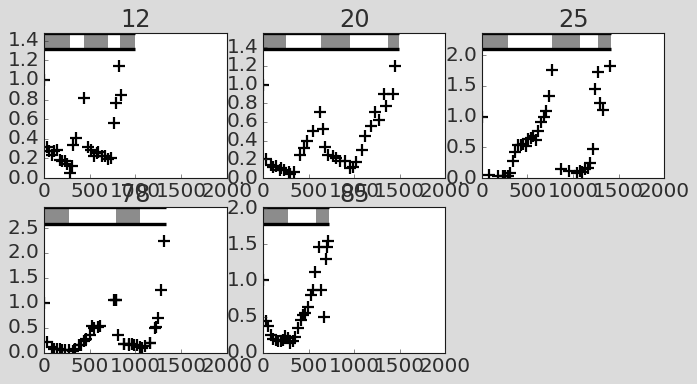

In [7]:
data_path = "../patients/Bruchovsky_et_al/Prog_data_txt"
patientIds = GetPatientIDs(data_path)
print("Loaded Patient IDs: " + str(patientIds))
patientIds = patientIds[:-2]  # Exclude two trickiest patients

plt.rcParams['font.size'] = '18'
fig, axs = plt.subplots(2, int((len(patientIds)+1)/2), figsize=(10, 5))
for i, patientId in enumerate(patientIds):
    dataDf = LoadPatientData(patientId, data_path)
    PlotData(dataDf, axs.flatten()[i], drugBarPosition=max(dataDf.PSA)*1.15,
             drugBarHeight=max(dataDf.PSA)*0.15)
    axs.flatten()[i].set_title(patientId)
    axs.flatten()[i].set_ylim(0, max(dataDf.PSA) * 1.3)
if len(patientIds) % 2 == 1: axs.flatten()[-1].axis('off');

In [41]:
# patientsToAnalyseList = [20, 78]  
patientsToAnalyseList = patientIds
solver_kws={'method':'RK45', 'absErr':1.0e-10, 'relErr':1.0e-10,
            'suppressOutputB':False}
optimiser_kws = {'method':'least_squares', 'xtol':1e-8, 'ftol':1e-8,
                 'max_nfev':200,'nan_policy':'omit', 'verbose':0}

# Model Parameters
model_name = "LotkaVolterraModel"; params = Parameters()
working_dir = os.path.join(out_dir, model_name)

# Variable Parameters
params.add('n0', min=0.1, max=1., vary=True); 
params.add('fR', min=1e-5, max=0.1, vary=True)
params.add('cost', min=0.1, max=0.5, vary=True)
params.add('turnover', min=0.1, max=1., vary=True)
params.add('K', value=1, min=0.5, max=5, vary=True)
params.add('rS', value=0.027, min=0.01, max=0.03, vary=True);

# Fixed/Calculated Parameters
# params.add('rS', value=0.027, vary=False); 
params.add('rR', expr='(1-cost)*rS', vary=False)
params.add('dS', expr='turnover*rS', vary=False); params.add('dR', expr='dS', vary=False)
params.add('dD', value=1.5, vary=False); params.add('theta', value=1, vary=False)
params.add('D', value=1, vary=False); params.add('DMax', value=1, vary=False)
params.add('S0', expr='n0*(1-fR)', vary=False); params.add('R0', expr='n0*fR', vary=False)

In [42]:
if RERUN_FITTING:
    for patientId in tqdm(patientsToAnalyseList):
        # Load data
        training_data_df = LoadPatientData(patientId, data_path)
        
        training_data_df = training_data_df.dropna(subset=['PSA']).reset_index(drop=True)
        
        # Setup env
        curr_out_dir = os.path.join(working_dir,"patient%d"%patientId)
        os.makedirs(curr_out_dir, exist_ok=True)
        tmp_model = LotkaVolterraModel()
        curr_params = Parameters()
        curr_params.add_many(*[params[x] for x in params.keys()])

        # Set up initial conditions
        if params['n0'].vary==False: curr_params['n0'].value = training_data_df.PSA.iloc[0]

        # Fit
        tmp_model.SetParams(**params)
        fit_obj = minimize(residual, params, args=(training_data_df, tmp_model, 
                                                        "PSA", solver_kws), **optimiser_kws)
        fit_obj.fitId = 0
        fit_obj.numericalStabilisation = tmp_model.numericalStabilisationB
        fit_obj.modelName = model_name
        fit_obj.data = training_data_df
        fit_obj.rSq = compute_r_sq(fit_obj, training_data_df, feature="PSA")

        # Post-process
        pickle.dump(obj=fit_obj, file=open(os.path.join(curr_out_dir,
                                                        "fitObj_fit_%d.p"%(fit_obj.fitId)), "wb"))

100%|██████████| 5/5 [00:43<00:00,  8.61s/it]


In [43]:
# Store patient parameters in a dataframe
if RERUN_FITTING:
    data = []
# Only loop through the patients we know we just processed
    for patientId in patientsToAnalyseList:
        patient_dir = f"patient{patientId}"
        full_path = os.path.join(out_dir, model_name, patient_dir)
        
        if os.path.exists(full_path):
            fitSummaryDf = generate_fitSummaryDf(full_path)
            print(os.path.join(out_dir, model_name, patient_dir))
            fitSummaryDf = generate_fitSummaryDf(os.path.join(out_dir, model_name, patient_dir))
            patient_id_match = re.findall(r'\d+', patient_dir)
            if patient_id_match:
                patient_id = int(patient_id_match[0])
                fitSummaryDf.insert(0, "PatientId", patient_id)
                data.append(fitSummaryDf)

    df = pd.concat(data, axis=0)
        
    df['TimeInTrial'] = df['PatientId'].apply(lambda x: \
        LoadPatientData(x, data_path).Time.max())
    df = df.sort_values(by="PatientId").reset_index(drop=True)
    df = df[df['PatientId'].isin(patientIds)]
    df['Cost'] = 1 - df['rR'] / df['rS']; df['Turnover'] = df['dS'] / df['rS']

    print(df[['PatientId', 'n0', 'fR', 'Turnover', 'Cost', 'K', 'rS']])

    #Test progression
    df['Progression'] = df.apply(lambda x: test_progression(x.to_dict()), axis=1)
    print("Progression: %d/%d"%(df.Progression.sum(), len(df)), end='')
    print(f"  ({[x for x in df.PatientId[df.Progression==True]]})")

    # Save patient params
    df.to_csv("patient_fits/full_history_params.csv", index=False)

else:
    df = pd.read_csv("patient_fits/full_history_params.csv")

../patients/Bruchovsky_et_al/Trunc_fits/LotkaVolterraModel/patient12
../patients/Bruchovsky_et_al/Trunc_fits/LotkaVolterraModel/patient20
../patients/Bruchovsky_et_al/Trunc_fits/LotkaVolterraModel/patient25
../patients/Bruchovsky_et_al/Trunc_fits/LotkaVolterraModel/patient78
../patients/Bruchovsky_et_al/Trunc_fits/LotkaVolterraModel/patient85
   PatientId        n0        fR  Turnover      Cost         K        rS
0         12  0.746497  0.000275  0.100000  0.106732  5.000000  0.013379
1         20  0.689043  0.000520  0.332780  0.100000  1.848775  0.013343
2         25  1.000000  0.000013  0.308907  0.100000  2.878192  0.019766
3         78  0.819174  0.000010  0.309977  0.100000  1.772190  0.022393
4         85  0.964177  0.033427  0.338499  0.414367  4.991763  0.027351
Progression: 5/5  ([12, 20, 25, 78, 85])


/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_58639/3256241650.py:19: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat(data, axis=0)


In [13]:
n = len(df['PatientId'].unique())
cols = [colormaps['tab10'](i/n) for i in range(n)]
markers = ['v', 's', 'X', 'P', 'o', '*', 'd',]

/Users/kitgallagher/Documents/Other/Oxford/Biomarkers Resubmission/Mathematical-Biomarkers/paper_figures/../utils/odeModelClass.py:49: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  self.paramDic[key] = float(kwargs.get(key, self.paramDic[key]))
/Users/kitgallagher/Documents/Other/Oxford/Biomarkers Resubmission/Mathematical-Biomarkers/paper_figures/../utils/odeModelClass.py:49: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  self.paramDic[key] = float(kwargs.get(key, self.paramDic[key]))
/Users/kitgallagher/Documents/Other/Oxford/Biomarkers Resubmission/Mathematical-Biomarkers/paper_figures/../utils/odeModelClass.py:49: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  self.paramDic[key] = float(kwarg

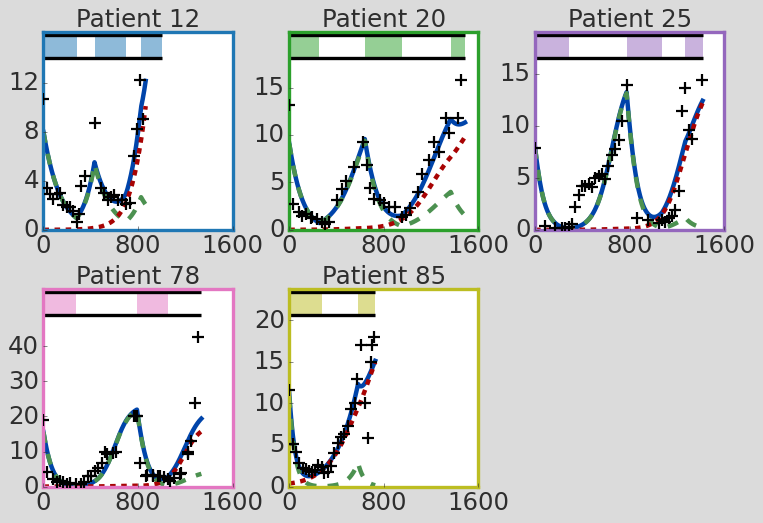

In [15]:
plt.rcParams['font.size'] = '22'
fig, axs = plt.subplots(2, int((len(patientIds)+1)/2), figsize=(10, 7))
for i, patientId in enumerate(patientIds):
    ax = axs.flatten()[i]
    dataDf = LoadPatientData(patientId, data_path)
    psa_scale = dataDf.PSA_raw[0]
    dataDf.PSA = dataDf.PSA * psa_scale
    PlotData(dataDf, ax, drugBarPosition=max(dataDf.PSA)*1.15, drug_col=cols[i],
             drugBarHeight=max(dataDf.PSA)*0.15, zorder=10, markersize=10)
    
    if patientId in patientsToAnalyseList:
        params = df[df.PatientId == patientId]
        myModel=LotkaVolterraModel()
        myModel.SetParams(**params)
        myModel.Simulate(treatmentScheduleList=ExtractTreatmentFromDf(dataDf),**solver_kws)
        myModel.Trim(dt=1)
        
        linestyles = ['-', (0, (10,10)), (0, (5,5))]
        col_vars = ['AT', 'Sensitive', 'Resistant']
        df_temp = myModel.resultsDf[myModel.resultsDf.TumourSize < max(dataDf.PSA) / psa_scale] 
        for j, var in enumerate(["TumourSize", 'S', 'R']):
            ax.plot(df_temp['Time'], df_temp[var]*psa_scale, linewidth=4, linestyle=linestyles[j], color=colors[col_vars[j]])

        ax.legend().remove()
    ax.set_title("Patient " +str(patientId), size=22); 
    ax.set_xticks([0, 800, 1600]); ax.set_xlim(0, 1600)
    
    ax.set_ylim(0, max(dataDf.PSA) * 1.32)
    if len(ax.get_yticks()) > 7: ax.set_yticks(ax.get_yticks()[::2])
    ax.set_yticks([x for x in ax.get_yticks() if x < max(dataDf.PSA) * 1.15])

    for loc in ['bottom', 'left', 'top', 'right']:
        ax.spines[loc].set_color(cols[i])
        ax.spines[loc].set_linewidth(3)
    
if len(patientIds) % 2 == 1: axs.flatten()[-1].axis('off');
plt.tight_layout()
plt.subplots_adjust(hspace=0.3, wspace=0.3)
plt.savefig("figures/Bruchovsky_summary.pdf", dpi=300, bbox_inches='tight')

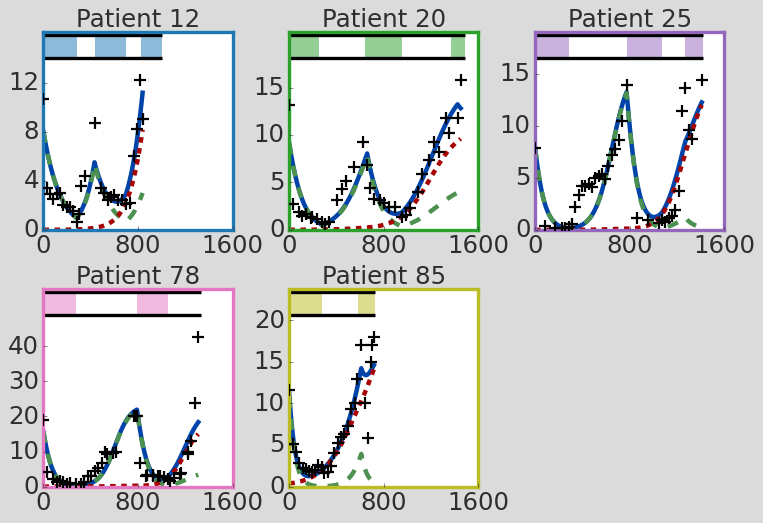

In [16]:
plt.rcParams['font.size'] = '22'
fig, axs = plt.subplots(2, int((len(patientIds)+1)/2), figsize=(10, 7))
for i, patientId in enumerate(patientIds):
    ax = axs.flatten()[i]
    dataDf = LoadPatientData(patientId, data_path)
    psa_scale = dataDf.PSA_raw[0]
    dataDf.PSA = dataDf.PSA * psa_scale
    PlotData(dataDf, ax, drugBarPosition=max(dataDf.PSA)*1.15, drug_col=cols[i],
             drugBarHeight=max(dataDf.PSA)*0.15, zorder=10, markersize=10)
    
    if patientId in patientsToAnalyseList:
        fitObj,myModel = load_fit(model_name,fitDir=os.path.join(working_dir,"patient%d"%patientId),
                             model=LotkaVolterraModel())
        myModel.Simulate(treatmentScheduleList=ExtractTreatmentFromDf(fitObj.data),**solver_kws)
        myModel.Trim(dt=1)
        
        linestyles = ['-', (0, (10,10)), (0, (5,5))]
        col_vars = ['AT', 'Sensitive', 'Resistant']
        df_temp = myModel.resultsDf[myModel.resultsDf.TumourSize < max(dataDf.PSA) / psa_scale] 
        for j, var in enumerate(["TumourSize", 'S', 'R']):
            ax.plot(df_temp['Time'], df_temp[var]*psa_scale, linewidth=4, linestyle=linestyles[j], color=colors[col_vars[j]])

        ax.legend().remove()
    ax.set_title("Patient " +str(patientId), size=22); 
    ax.set_xticks([0, 800, 1600]); ax.set_xlim(0, 1600)
    
    ax.set_ylim(0, max(dataDf.PSA) * 1.32)
    if len(ax.get_yticks()) > 7: ax.set_yticks(ax.get_yticks()[::2])
    ax.set_yticks([x for x in ax.get_yticks() if x < max(dataDf.PSA) * 1.15])

    for loc in ['bottom', 'left', 'top', 'right']:
        ax.spines[loc].set_color(cols[i])
        ax.spines[loc].set_linewidth(3)
    
if len(patientIds) % 2 == 1: axs.flatten()[-1].axis('off');
plt.tight_layout()
plt.subplots_adjust(hspace=0.3, wspace=0.3)
plt.savefig("figures/Bruchovsky_summary.pdf", dpi=300, bbox_inches='tight')

5it [00:05,  1.16s/it]


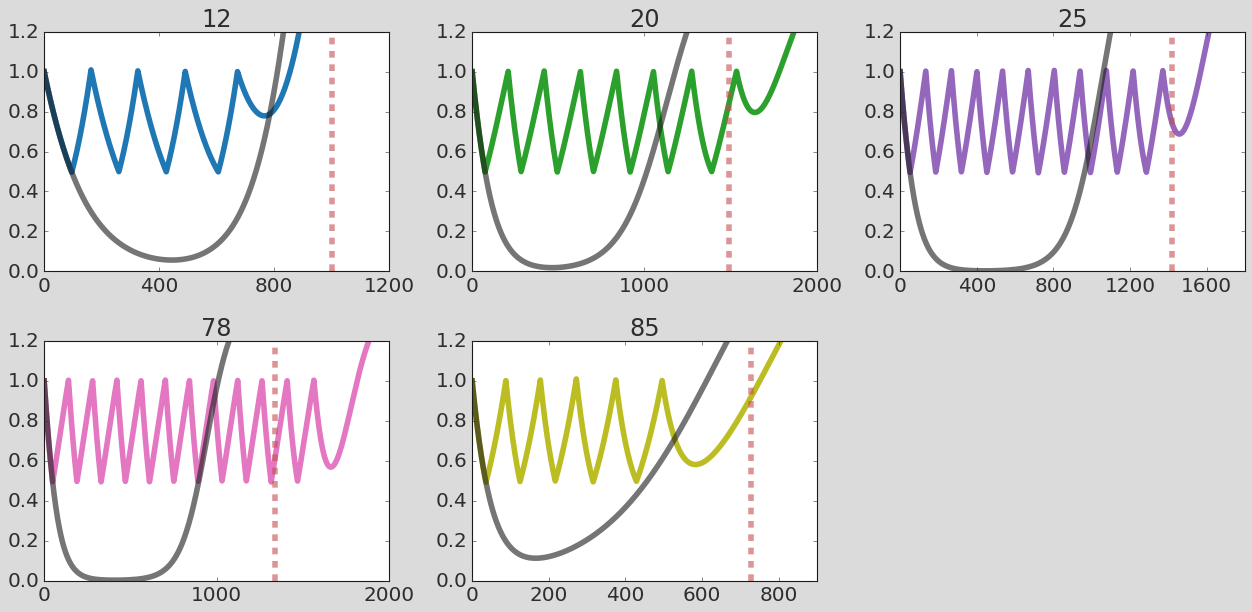

In [17]:
# Plot response to AT
plt.rcParams['font.size'] = '18'
fig, axs = plt.subplots(2, int((len(patientIds)+1)/2), figsize=(16, 8))
for i, patientId in tqdm(enumerate(patientIds)):
    params = df.loc[df.PatientId==patientId].iloc[0].to_dict()
    ax = axs.flatten()[i]
    at_model = LotkaVolterraModel(dt=1); at_model.SetParams(**params)
    at_model.Simulate_AT(t_end=5000); at_model.CleanData(); 
    ax.plot(at_model.resultsDf.Time, at_model.resultsDf.TumourSize,
                            color=cols[i], label='AT', linewidth=5)
    
    ct_model = LotkaVolterraModel(dt=1); ct_model.SetParams(**params)
    ct_model.Simulate([[0, 5000, 1]]); ct_model.CleanData(); 
    ax.plot(ct_model.resultsDf.Time, ct_model.resultsDf.TumourSize,
                            color='k', alpha=0.6, label='CT', linewidth=5)
    
    trial_prog = df.loc[df.PatientId==patientId].TimeInTrial
    ax.vlines(trial_prog, 0, at_model.resultsDf.TumourSize.max() * 1.3,
                            color='r', linestyle='--', alpha=0.6, 
                            label='Trial TTP', linewidth=5)

    ax.set_title(patientId); ax.set_xticks(ax.get_xticks()[::2])
    if i != 0: axs.flatten()[i].legend().remove()
    ax.set_ylim(0, 1.2)
    
if len(patientIds) % 2 == 1: axs.flatten()[-1].axis('off');
plt.tight_layout()

In [18]:
# Plot response to AT
plt.rcParams['font.size'] = '18'
ttp_baselines = []
ttp_nadirs = []
patient_order = []

# `df` may have been overwritten later (e.g., df = n-2); restore parameter table if needed.
if not isinstance(df, pd.DataFrame):
    df = pd.read_csv("patient_fits/full_history_params.csv")

def _ttp_metrics_from_results(results_df):
    t = results_df["Time"].to_numpy()
    x = results_df["TumourSize"].to_numpy()
    d = results_df["DrugConcentration"].to_numpy()

    # ttp_baseline: first time tumour exceeds 1.2 * initial tumour size
    baseline_hits = np.where(x >= 1.2 * x[0])[0]
    ttp_baseline = t[baseline_hits[0]] if len(baseline_hits) else t[-1]

    # tt_nadir: in the last on-treatment period, first time tumour exceeds 1.25 * period start size
    on = d > 0
    starts = np.where(on & ~np.r_[False, on[:-1]])[0]
    ends = np.where(on & ~np.r_[on[1:], False])[0]

    if len(starts):
        s0, e0 = starts[-1], ends[-1]
        period_x = x[s0:e0 + 1]

        # Use 1.25 * minimum tumour size (nadir) in the last on-treatment period
        nadir_rel_idx = np.argmin(period_x)
        nadir_idx = s0 + nadir_rel_idx
        threshold = 1.25 * period_x[nadir_rel_idx]

        # First time (from nadir onward) tumour exceeds nadir-based threshold
        local_hits = np.where(x[nadir_idx:e0 + 1] >= threshold)[0]
        tt_nadir = t[nadir_idx + local_hits[0]] if len(local_hits) else np.nan
    else:
        tt_nadir = np.nan

    return ttp_baseline, tt_nadir

for i, patientId in tqdm(enumerate(patientIds)):
    params = df.loc[df.PatientId==patientId].iloc[0].to_dict()
    ax = axs.flatten()[i]
    at_model = LotkaVolterraModel(dt=1); at_model.SetParams(**params)
    at_model.Simulate_AT(t_end=5000); at_model.CleanData(); 

    ttp_baseline, tt_nadir = _ttp_metrics_from_results(at_model.resultsDf)
    ttp_baselines.append(ttp_baseline)
    ttp_nadirs.append(tt_nadir)

5it [00:04,  1.21it/s]


In [19]:
print(ttp_nadirs)
print(ttp_baselines)

[np.float64(851.0), np.float64(1781.0), np.float64(1537.0), np.float64(1737.0), np.float64(668.0)]
[np.float64(887.0), np.float64(1867.0), np.float64(1612.0), np.float64(1883.0), np.float64(806.0)]


In [20]:
# Compare patient ordering and scaling between ttp_baseline and tt_nadir

# Build paired table
metrics_df = pd.DataFrame({
    "PatientId": patientIds,
    "ttp_baseline": ttp_baselines,
    "tt_nadir": ttp_nadirs
})


valid_df = metrics_df.dropna(subset=["ttp_baseline", "tt_nadir"]).copy()

print("Paired metrics:")
print(metrics_df)

if len(valid_df) < 3:
    print("\nNot enough non-NaN paired values for reliable correlation/scaling tests.")
else:
    x = valid_df["ttp_baseline"].to_numpy(dtype=float)
    y = valid_df["tt_nadir"].to_numpy(dtype=float)

    # 1) Do they rank patients the same?
    order_baseline = valid_df.sort_values("ttp_baseline")["PatientId"].tolist()
    order_nadir = valid_df.sort_values("tt_nadir")["PatientId"].tolist()
    exact_same_order = order_baseline == order_nadir

    spearman_rho, spearman_p = sc.stats.spearmanr(x, y)
    kendall_tau, kendall_p = sc.stats.kendalltau(x, y)

    print("\nRanking comparison:")
    print("Order by ttp_baseline:", order_baseline)
    print("Order by tt_nadir   :", order_nadir)
    print(f"Exact same order: {exact_same_order}")
    print(f"Spearman rho = {spearman_rho:.3f}, p = {spearman_p:.4g}")
    print(f"Kendall tau  = {kendall_tau:.3f}, p = {kendall_p:.4g}")

    # 2) Is one approximately a constant scaling of the other? (tt_nadir ≈ k * ttp_baseline)
    # Through-origin slope estimate
    k_hat = np.sum(x * y) / np.sum(x ** 2)
    y_hat0 = k_hat * x
    sse0 = np.sum((y - y_hat0) ** 2)
    r2_origin = 1 - sse0 / np.sum(y ** 2)

    # Ratio diagnostics
    ratios = y / x
    ratio_mean = np.mean(ratios)
    ratio_std = np.std(ratios, ddof=1) if len(ratios) > 1 else np.nan
    ratio_cv = ratio_std / ratio_mean if np.isfinite(ratio_std) and ratio_mean != 0 else np.nan

    # Linear model with intercept (checks whether intercept is ~0)
    slope, intercept, r_value, p_value_linear, std_err = sc.stats.linregress(x, y)

    # Intercept significance test
    n_pairs = len(x)
    sxx = np.sum((x - np.mean(x)) ** 2)
    y_fit = intercept + slope * x
    sse = np.sum((y - y_fit) ** 2)
    s_yx = np.sqrt(sse / (n_pairs - 2))
    se_intercept = s_yx * np.sqrt(1 / n_pairs + (np.mean(x) ** 2) / sxx)
    t_intercept = intercept / se_intercept
    p_intercept = 2 * (1 - sc.stats.t.cdf(np.abs(t_intercept), df=n_pairs - 2))

    print("\nScaling hypothesis (tt_nadir ≈ k * ttp_baseline):")
    print(f"k (through origin) = {k_hat:.3f}")
    print(f"R² (through origin) = {r2_origin:.3f}")
    print(f"Mean ratio y/x = {ratio_mean:.3f}, SD = {ratio_std:.3f}, CV = {ratio_cv:.3f}")
    print(f"With intercept: slope = {slope:.3f}, intercept = {intercept:.3f}, R² = {r_value**2:.3f}")
    print(f"Intercept test: t = {t_intercept:.3f}, p = {p_intercept:.4g}")

    # 3) Is tt_nadir consistently greater than ttp_baseline?
    diffs = y - x
    n_pos = np.sum(diffs > 0)
    n_nonzero = np.sum(diffs != 0)

    # Sign test (binomial, one-sided: P(diff > 0) > 0.5)
    sign_p = np.nan
    if n_nonzero > 0:
        sign_p = sc.stats.binomtest(n_pos, n_nonzero, p=0.5, alternative='greater').pvalue

    # Wilcoxon signed-rank (one-sided: tt_nadir > ttp_baseline)
    try:
        wilcoxon_stat, wilcoxon_p = sc.stats.wilcoxon(y, x, alternative='greater', zero_method='wilcox')
    except ValueError:
        wilcoxon_stat, wilcoxon_p = np.nan, np.nan

    print("\nPaired greater-than tests (tt_nadir > ttp_baseline):")
    print(f"Sign test: {n_pos}/{n_nonzero} positive, p = {sign_p:.4g}")
    print(f"Wilcoxon signed-rank: W = {wilcoxon_stat}, p = {wilcoxon_p:.4g}")

Paired metrics:
   PatientId  ttp_baseline  tt_nadir
0         12         887.0     851.0
1         20        1867.0    1781.0
2         25        1612.0    1537.0
3         78        1883.0    1737.0
4         85         806.0     668.0

Ranking comparison:
Order by ttp_baseline: [85, 12, 25, 20, 78]
Order by tt_nadir   : [85, 12, 25, 78, 20]
Exact same order: False
Spearman rho = 0.900, p = 0.03739
Kendall tau  = 0.800, p = 0.08333

Scaling hypothesis (tt_nadir ≈ k * ttp_baseline):
k (through origin) = 0.937
R² (through origin) = 0.999
Mean ratio y/x = 0.924, SD = 0.055, CV = 0.060
With intercept: slope = 0.981, intercept = -69.738, R² = 0.993
Intercept test: t = -0.956, p = 0.4095

Paired greater-than tests (tt_nadir > ttp_baseline):
Sign test: 0/5 positive, p = 1
Wilcoxon signed-rank: W = 0.0, p = 1


In [21]:
## Varying the adaptive threshold

def calc_ttp(params, interval=1, threshold=0.5):
    model = LotkaVolterraModel()
    model.SetParams(**params)
    model.Simulate_AT(atThreshold=threshold, intervalLength=interval, t_end=5000, atMethod='Zhang')
    return model.ttp

Patient 12: Difference of 81 days
Patient 20: Difference of 1247 days
Patient 25: Difference of 958 days
Patient 78: Difference of 1920 days
Patient 85: Difference of 310 days


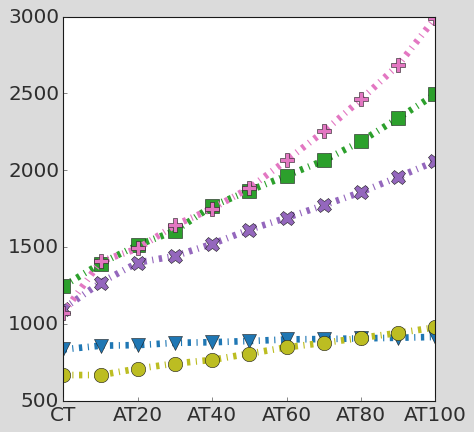

In [22]:
# Perfect AT (Interval of 1)

fix, ax = plt.subplots(1,1,figsize=(6,6))
plt.rcParams['font.size'] = '18'

threshold_vals = np.linspace(0, 1.0, 11);# threshold_vals[-1] = 1.01
# threshold_vals = np.linspace(0.2, 0.8, 3)

for i, patientId in enumerate(patientIds):
    params = df.loc[df.PatientId==patientId].iloc[0].to_dict()
    ttp_vals = [calc_ttp(params, threshold=threshold) for threshold in threshold_vals]
    ax.plot(threshold_vals, ttp_vals, linewidth=6, color=cols[i], linestyle='-.', 
            marker=markers[i], markersize=13)
    
    print(f"Patient {patientId}: Difference of {int(ttp_vals[-1] - ttp_vals[0])} days")

plt.tick_params(right = False, top = False); plt.xlim(0, 1); #plt.ylim(400, 1100)

x_ticks = ax.get_xticks()
x_labels = ['AT' + str(int(100 * x)) for x in x_ticks]; x_labels[0] = 'CT'
ax.set_xticks(x_ticks); ax.set_xticklabels(x_labels)

# ax.set_xlabel("Adaptive threshold"); ax.set_ylabel("Time to progression")
plt.savefig("figures/Fig1c_AT_thresholds_bruch.pdf")

Patient 12: Difference of -661 days
Patient 20: Difference of 1032 days
Patient 25: Difference of 824 days
Patient 78: Difference of 1370 days
Patient 85: Difference of -577 days


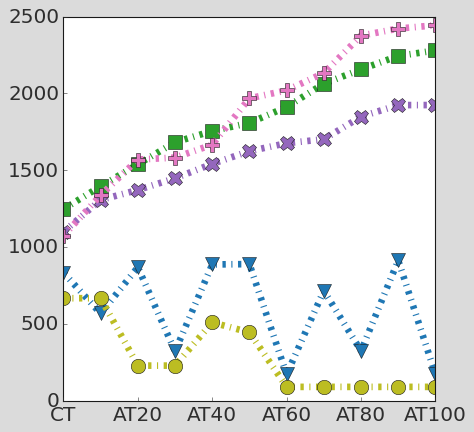

In [23]:
# Imperfect AT - Interval of 30 

fix, ax = plt.subplots(1,1,figsize=(6,6))
plt.rcParams['font.size'] = '18'

threshold_vals = np.linspace(0, 1.0, 11);# threshold_vals[-1] = 1.01
# threshold_vals = np.linspace(0.2, 0.8, 3)

for i, patientId in enumerate(patientIds):
    params = df.loc[df.PatientId==patientId].iloc[0].to_dict()
    ttp_vals = [calc_ttp(params, interval=30, threshold=threshold) for threshold in threshold_vals]
    ax.plot(threshold_vals, ttp_vals, linewidth=6, color=cols[i], linestyle='-.', 
            marker=markers[i], markersize=13)
    
    print(f"Patient {patientId}: Difference of {int(ttp_vals[-1] - ttp_vals[0])} days")

plt.tick_params(right = False, top = False); plt.xlim(0, 1); #plt.ylim(400, 1100)

x_ticks = ax.get_xticks()
x_labels = ['AT' + str(int(100 * x)) for x in x_ticks]; x_labels[0] = 'CT'
ax.set_xticks(x_ticks); ax.set_xticklabels(x_labels);

# ax.set_xlabel("Adaptive threshold"); ax.set_ylabel("Time to progression")
# plt.savefig("figures/Fig1c_AT_thresholds_bruch.pdf")

Patient 12: Difference of 81 days
Patient 20: Difference of 1247 days
Patient 25: Difference of 958 days


KeyboardInterrupt: 

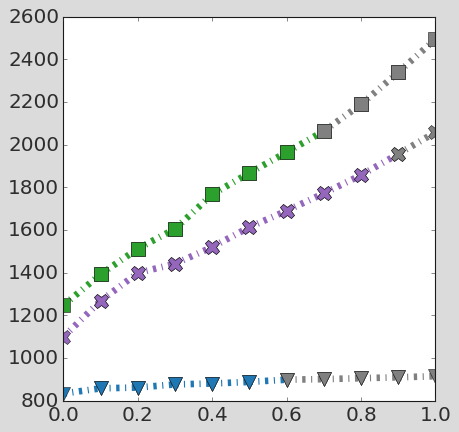

In [24]:
# Perfect AT - infeasible strategies grayed out 

fix, ax = plt.subplots(1,1,figsize=(6,6))
plt.rcParams['font.size'] = '18'

threshold_vals = np.linspace(0, 1.0, 11);# threshold_vals[-1] = 1.01
# threshold_vals = np.linspace(0.2, 0.8, 3)


for i, patientId in enumerate(patientIds):
    params = df.loc[df.PatientId==patientId].iloc[0].to_dict()
    ttp_vals = [calc_ttp(params, interval=1,threshold=threshold) for threshold in threshold_vals]
    critical_threshold = calc_critical_treatment_threshold(tau=30, **params)
    
    colors_list = [cols[i] if threshold <= critical_threshold else 'gray' for threshold in threshold_vals]
    for j, threshold in enumerate(threshold_vals):
        if j > 0:
            ax.plot(threshold_vals[j-1:j+1], ttp_vals[j-1:j+1], linewidth=6, color=colors_list[j], linestyle='-.', 
                marker=markers[i], markersize=13)
    
    print(f"Patient {patientId}: Difference of {int(ttp_vals[-1] - ttp_vals[0])} days")

plt.tick_params(right = False, top = False); plt.xlim(0, 1); #plt.ylim(400, 1100)

x_ticks = ax.get_xticks()
x_labels = ['AT' + str(int(100 * x)) for x in x_ticks]; x_labels[0] = 'CT'
ax.set_xticks(x_ticks); ax.set_xticklabels(x_labels)
ax.set_xlim(-0.03, 1.03)

# ax.set_xlabel("Adaptive threshold"); ax.set_ylabel("Time to progression")
plt.savefig("figures/Fig1c_AT_thresholds_bruch_mask.pdf")

## Fit to first cycle only

These parameter values can then subsequently be used for validation later.

In [8]:
out_dir = os.path.join(os.pardir, "patients", "Bruchovsky_et_al", "Trunc_fits")

patientsToAnalyseList = patientIds
solver_kws={'method':'RK45', 'absErr':1.0e-10, 'relErr':1.0e-10,
            'suppressOutputB':False}
optimiser_kws = {'method':'least_squares', 'xtol':1e-8, 'ftol':1e-8,
                 'max_nfev':200,'nan_policy':'omit', 'verbose':0}

# Model Parameters
model_name = "LotkaVolterraModel"; params = Parameters()
working_dir = os.path.join(out_dir, model_name)

# New
params.add('turnover', min=0.01, max=1., vary=True)
params.add('K', value=3, min=2.5, max=5, vary=True)

# Fixed from historical data/estimates
params.add('fR', value=1e-5, vary=False)
params.add('cost', value=0.1, vary=False)
params.add('rS', value=0.027, vary=False)
params.add('n0', value=0.1, vary=False)  # Will be matched to initial value

# Fixed/Calculated Parameters
params.add('rR', expr='(1-cost)*rS', vary=False)
params.add('dS', expr='turnover*rS', vary=False); params.add('dR', expr='dS', vary=False)
params.add('dD', value=1.5, vary=False); params.add('theta', value=1, vary=False)
params.add('D', value=1, vary=False); params.add('DMax', value=1, vary=False)
params.add('S0', expr='n0*(1-fR)', vary=False); params.add('R0', expr='n0*fR', vary=False)

In [9]:
if RERUN_FITTING:
    for patientId in tqdm(patientsToAnalyseList):
        # Load data
        training_data_df = LoadPatientData(patientId, data_path)
        training_data_df = training_data_df.dropna(subset=['PSA']).reset_index()

        last_cycle1_index = training_data_df[training_data_df['CycleId'] == 1].index[-1]
        
        training_data_df = training_data_df[:last_cycle1_index+2]
        
        # Setup env
        curr_out_dir = os.path.join(working_dir,"patient%d"%patientId)
        os.makedirs(curr_out_dir, exist_ok=True)
        tmp_model = LotkaVolterraModel()
        curr_params = Parameters()
        curr_params.add_many(*[params[x] for x in params.keys()])

        # Set up initial conditions
        if params['n0'].vary==False: curr_params['n0'].value = training_data_df.PSA.iloc[0]

        # Fit
        tmp_model.SetParams(**params)
        fit_obj = minimize(residual, params, args=(training_data_df, tmp_model, 
                                                        "PSA", solver_kws), **optimiser_kws)
        fit_obj.fitId = 0
        fit_obj.numericalStabilisation = tmp_model.numericalStabilisationB
        fit_obj.modelName = model_name
        fit_obj.data = training_data_df
        fit_obj.rSq = compute_r_sq(fit_obj, training_data_df, feature="PSA")

        # Post-process
        pickle.dump(obj=fit_obj, file=open(os.path.join(curr_out_dir,
                                                        "fitObj_fit_%d.p"%(fit_obj.fitId)), "wb"))

100%|██████████| 5/5 [00:03<00:00,  1.26it/s]


In [10]:
# Store patient parameters in a dataframe
if RERUN_FITTING:
    trunc_df = pd.DataFrame()
    for patientId in patientsToAnalyseList:
        patient_dir = f"patient{patientId}"
        full_path = os.path.join(out_dir, model_name, patient_dir)
        
        if os.path.exists(full_path):
            fitSummaryDf = generate_fitSummaryDf(full_path)
            fitSummaryDf.insert(0, "PatientId",  int(re.findall(r'\d+', patient_dir)[0]))
            trunc_df = pd.concat([trunc_df, fitSummaryDf], axis=0)
        
    trunc_df['TimeInTrial'] = trunc_df['PatientId'].apply(lambda x: \
        LoadPatientData(x, data_path).Time.max())
    trunc_df = trunc_df.sort_values(by="PatientId").reset_index()
    trunc_df = trunc_df[trunc_df['PatientId'].isin(patientIds)]
    trunc_df['Cost'] = 1 - trunc_df['rR'] / trunc_df['rS']; 
    trunc_df['Turnover'] = trunc_df['dS'] / trunc_df['rS']
    # trunc_df['K'] = 2.5

    print(trunc_df[['PatientId', 'n0', 'fR', 'Turnover', 'Cost', 'K', 'rS']])

    #Test progression
    trunc_df['Progression'] = trunc_df.apply(lambda x: test_progression(x.to_dict()), axis=1)
    print("Progression: %d/%d"%(trunc_df.Progression.sum(), len(trunc_df)), end='')
    print(f"  ({[x for x in trunc_df.PatientId[trunc_df.Progression==True]]})")

    # Save patient params
    trunc_df.to_csv("patient_fits/first_cycle_params.csv", index=False)
else:
    trunc_df = pd.read_csv("patient_fits/first_cycle_params.csv")

   PatientId   n0       fR  Turnover  Cost    K     rS
0         12  1.0  0.00001  0.053555   0.1  5.0  0.027
1         20  1.0  0.00001  0.356593   0.1  2.5  0.027
2         25  1.0  0.00001  0.309963   0.1  2.5  0.027
3         78  1.0  0.00001  0.393746   0.1  2.5  0.027
4         85  1.0  0.00001  0.228722   0.1  2.5  0.027
Progression: 5/5  ([12, 20, 25, 78, 85])


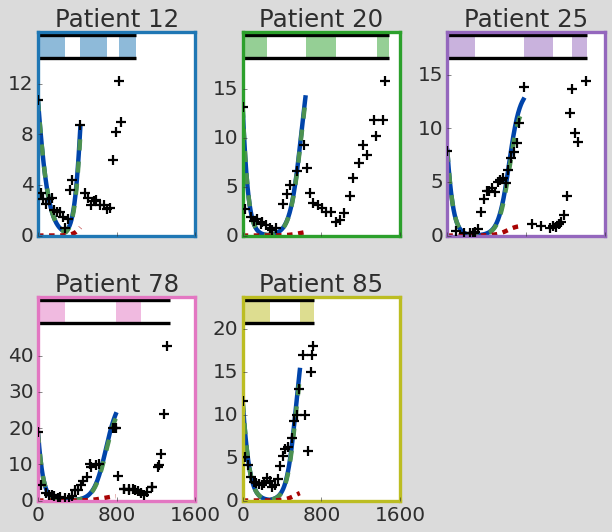

In [37]:
plt.rcParams['font.size'] = '18'
fig, axs = plt.subplots(2, 3, figsize=(8, 7), sharex=True)

for i, patientId in enumerate(patientIds):
    ax = axs.flatten()[i]
    dataDf = LoadPatientData(patientId, data_path)
    psa_scale = dataDf.PSA_raw[0]
    dataDf.PSA = dataDf.PSA * psa_scale
    PlotData(dataDf, ax, drugBarPosition=max(dataDf.PSA)*1.15, drug_col=cols[i],
             drugBarHeight=max(dataDf.PSA)*0.15, zorder=10, markersize=9)
    
    if patientId in patientsToAnalyseList:
        patient_params = trunc_df[trunc_df['PatientId'] == patientId].iloc[0]
        treatment_schedule = ExtractTreatmentFromDf(dataDf)
        
        myModel = LotkaVolterraModel(); myModel.SetParams(**patient_params.to_dict())
        myModel.Simulate(treatmentScheduleList=treatment_schedule, **solver_kws)
        myModel.Trim(dt=1)
        df_temp = TruncateDataframe(myModel.resultsDf, drug_name = 'DrugConcentration')
        
        linestyles = ['-', (0, (10,10)), (0, (5,5))]
        col_vars = ['AT', 'Sensitive', 'Resistant']       
        for j, var in enumerate(["TumourSize", 'S', 'R']):
            ax.plot(df_temp['Time'], df_temp[var] * psa_scale, linewidth=4, linestyle=linestyles[j], color=colors[col_vars[j]])
        ax.legend().remove()
    
    ax.set_title("Patient " + str(patientId), size=22)
    ax.set_xticks([0, 800, 1600])
    ax.set_xlim(0, 1600)
    
    ax.set_ylim(0, max(dataDf.PSA) * 1.32)
    if len(ax.get_yticks()) > 7:
        ax.set_yticks(ax.get_yticks()[::2])
    ax.set_yticks([x for x in ax.get_yticks() if x < max(dataDf.PSA) * 1.15])

    for loc in ['bottom', 'left', 'top', 'right']:
        ax.spines[loc].set_color(cols[i])
        ax.spines[loc].set_linewidth(3)
    
if len(patientIds) % 2 == 1:
    axs.flatten()[-1].axis('off')

plt.tight_layout()
plt.subplots_adjust(hspace=0.3, wspace=0.3)
plt.savefig("figures/Bruchovsky_trunc_summary.pdf", dpi=300, bbox_inches='tight')

## Parameter Value Comparison


In [38]:
def simulate_doubling_time(params):
    model = LotkaVolterraModel()
    model.SetParams(**params)
    model.Simulate([[0, 2000, 0]])
    model.resultsDf = model.resultsDf[model.resultsDf.TumourSize < params['n0']*1.2]
    # plt.plot(model.resultsDf.Time, model.resultsDf.TumourSize)
    
    return model.resultsDf.Time.max()

In [47]:
# Generate a table with patient id, predicted doubling time, and true doubling time
doubling_time_data = []

for patientId in patientIds:
    param_sets = [trunc_df.loc[trunc_df.PatientId == patientId].iloc[0].to_dict(),
                  df.loc[df.PatientId == patientId].iloc[0].to_dict()]
    doubling_times = [simulate_doubling_time(param_set) for param_set in param_sets]
    doubling_time_data.append([patientId, doubling_times[0], doubling_times[1]])

doubling_time_df = pd.DataFrame(doubling_time_data, columns=['PatientId', 'PredictedDoublingTime', 'TrueDoublingTime'])
print(doubling_time_df)

   PatientId  PredictedDoublingTime  TrueDoublingTime
0         12                 13.329            18.513
1         20                 33.433            53.262
2         25                 27.107            29.884
3         78                 41.123            45.492
4         85                 20.408            15.180


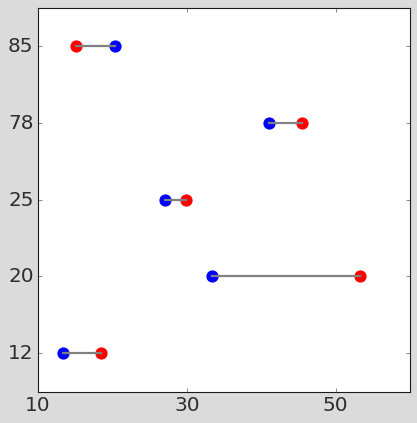

In [48]:
# Dumbbell plot to compare sensitive doubling times
fig, ax = plt.subplots(figsize=(6, 6))

for i in range(len(df)):
    ax.plot([doubling_time_df['PredictedDoublingTime'][i], 
             doubling_time_df['TrueDoublingTime'][i]], 
            [i, i], color='grey', lw=2)

ax.scatter(doubling_time_df['PredictedDoublingTime'], range(len(df)), 
           color='blue', s=100, label='First Cycle Prediction')
ax.scatter(doubling_time_df['TrueDoublingTime'], range(len(df)), 
           color='red', s=100, label='Ground Truth')

# Customize the plot
ax.set_xticks(ax.get_xticks()[::2])
ax.set_yticks(range(len(doubling_time_df)))
ax.set_yticklabels(doubling_time_df['PatientId']); ax.set_ylim(-0.5, 4.5)
# ax.set_xlabel('Growth Timescale (days)'); ax.set_ylabel('Patient ID')
# ax.legend()

plt.show()

In [49]:
print(colors)

{'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT': '#c28d32', 'AT': '#0044AA', 'DRL_Monthly': '#66419e'}


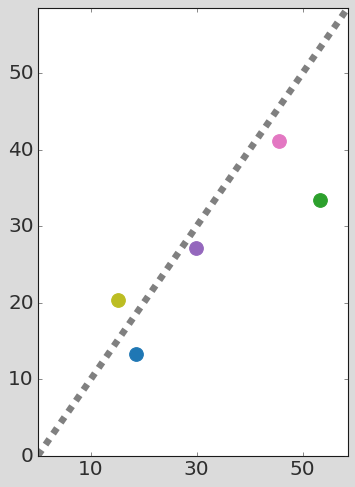

In [50]:
scale_extension = 1.1

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(figsize=(5, 7))
for i, patientId in enumerate(doubling_time_df['PatientId']):
    ax.scatter(doubling_time_df.loc[doubling_time_df['PatientId'] == patientId, 'TrueDoublingTime'],
               doubling_time_df.loc[doubling_time_df['PatientId'] == patientId, 'PredictedDoublingTime'],
               color=cols[i], s=150, label=f'Patient {patientId}')
max_time = max(doubling_time_df['TrueDoublingTime'].max(), 
               doubling_time_df['PredictedDoublingTime'].max())
ax.plot([0, max_time * scale_extension], [0, max_time*scale_extension], 
        linestyle='--', linewidth=6, color='gray', label='Guide Line')

ax.set_xticks(ax.get_xticks()[::2])
# ax.set_xlabel('True Doubling Time'); ax.set_ylabel('Predicted Doubling Time')
ax.set_xlim(0, max_time*scale_extension); ax.set_ylim(0, max_time*scale_extension)
# ax.legend(loc=2)
plt.savefig("figures/doubling_time_comparison.pdf", dpi=300, bbox_inches='tight')

In [51]:
from scipy.stats import linregress, pearsonr, spearmanr, kendalltau, t
# Linear regression
slope, intercept, r_value, p_value_linear, std_err = linregress(
    doubling_time_df['PredictedDoublingTime'], doubling_time_df['TrueDoublingTime']
)

# slope uncertainty = standard error from linregress
print("Linear Regression:")
print(f"  R² = {r_value**2:.4f}")
print(f"  p-value = {p_value_linear:.4f}")
print(f"  slope = {slope:.4f} ± {std_err:.4f}")
print(f"  intercept = {intercept:.4f}")

# Spearman's rank correlation
spearman_rho, p_value_spearman = spearmanr(doubling_time_df['PredictedDoublingTime'], doubling_time_df['TrueDoublingTime'])
print(f"\nSpearman's Rank Correlation:")
print(f"  rho = {spearman_rho:.4f}")
print(f"  p-value = {p_value_spearman:.4f}")

# Kendall's tau
tau, p_value_kendall = kendalltau(doubling_time_df['PredictedDoublingTime'], doubling_time_df['TrueDoublingTime'])
print(f"\nKendall's Tau:")
print(f"  tau = {tau:.4f}")
print(f"  p-value = {p_value_kendall:.4f}")

Linear Regression:
  R² = 0.7453
  p-value = 0.0594
  slope = 1.3205 ± 0.4457
  intercept = -3.2922

Spearman's Rank Correlation:
  rho = 0.8000
  p-value = 0.1041

Kendall's Tau:
  tau = 0.6000
  p-value = 0.2333


In [52]:
# Your existing linear regression
slope, intercept, r_value, p_value_linear, std_err = linregress(
    doubling_time_df['PredictedDoublingTime'], doubling_time_df['TrueDoublingTime']
)

n = len(doubling_time_df)
df = n - 2

t_critical = t.ppf(0.975, df)

margin_of_error = t_critical * std_err
ci_lower = slope - margin_of_error
ci_upper = slope + margin_of_error

print("Linear Regression Validation:")
print(f"  R² = {r_value**2:.2f}")
print(f"  slope = {slope:.2f} (95% CI, {ci_lower:.2f}-{ci_upper:.2f})")

Linear Regression Validation:
  R² = 0.75
  slope = 1.32 (95% CI, -0.10-2.74)
